In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=128
)



/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.8099 - loss: 0.5345 - val_accuracy: 0.8602 - val_loss: 0.3935
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8639 - loss: 0.3721 - val_accuracy: 0.8664 - val_loss: 0.3743
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8762 - loss: 0.3343 - val_accuracy: 0.8775 - val_loss: 0.3362
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8841 - loss: 0.3086 - val_accuracy: 0.8699 - val_loss: 0.3636
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.8910 - loss: 0.2923 - val_accuracy: 0.8490 - val_loss: 0.4045
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8964 - loss: 0.2750 - val_accuracy: 0.8836 - val_loss: 0.3226
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.9005 - loss: 0.2629 - val_accuracy: 0.8862 - val_loss: 0.3168
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9074 - loss: 0.2483 - val_accu

In [4]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [5]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import AdamW

# Check dataset shapes
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)
print("Y_train shape:", y_train.shape)
print("Y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
Y_train shape: (60000,)
Y_test shape: (10000,)


In [6]:
# 1. Convert data to float32
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

# 2. Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# 4. Check new shapes
print("X_train shape:", x_train.shape)
print("X_test shape:", x_test.shape)

X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)


In [7]:
# 1. Build CNN Model

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

# Display model architecture
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Combined Loss Function

def combined_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int64)

    y_true_one_hot = tf.one_hot(y_true, depth=10)

    cross_entropy = tf.keras.losses.categorical_crossentropy(
        y_true_one_hot, y_pred
    )

    mse = tf.reduce_mean(
        tf.square(y_true_one_hot - y_pred), axis=-1
    )

    return cross_entropy + 0.1 * mse

In [9]:
# Compile CNN Model with AdamW

optimizer = AdamW(
    learning_rate=0.001,
    weight_decay=0.0001
)

model.compile(
    optimizer=optimizer,
    loss=combined_loss,
    metrics=['accuracy']
)

In [10]:
history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 106ms/step - accuracy: 0.9224 - loss: 0.2607 - val_accuracy: 0.9835 - val_loss: 0.0625
Epoch 2/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 105ms/step - accuracy: 0.9777 - loss: 0.0746 - val_accuracy: 0.9878 - val_loss: 0.0417
Epoch 3/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 105ms/step - accuracy: 0.9839 - loss: 0.0521 - val_accuracy: 0.9878 - val_loss: 0.0382
Epoch 4/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 108ms/step - accuracy: 0.9866 - loss: 0.0432 - val_accuracy: 0.9897 - val_loss: 0.0388
Epoch 5/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9883 - loss: 0.0371 - val_accuracy: 0.9895 - val_loss: 0.0388
Epoch 6/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 105ms/step - accuracy: 0.9906 - loss: 0.0300 - val_accuracy: 0.9885 - val_loss: 0.0369
Epoch 7/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 105ms/step - accuracy: 0.9917 - loss: 0.0262 - val_accuracy: 0.9905 - val_loss: 0.0319
Epoch 8/50
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 106ms/step - accuracy: 0.9928 - loss: 0

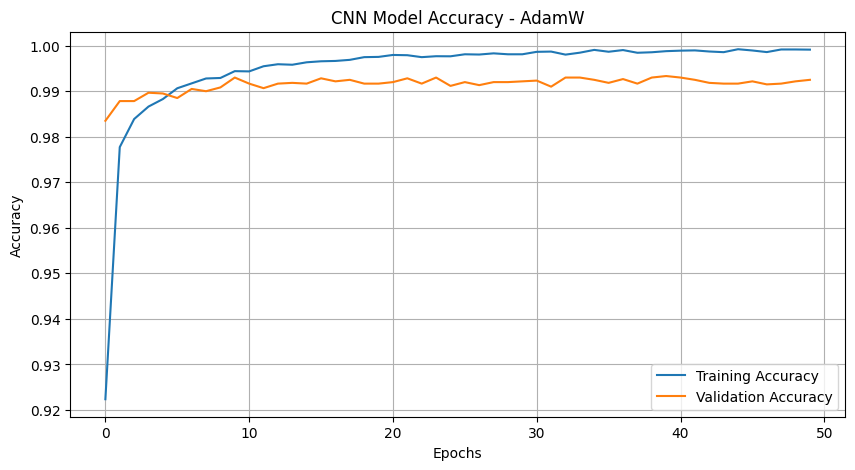

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('CNN Model Accuracy - AdamW')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

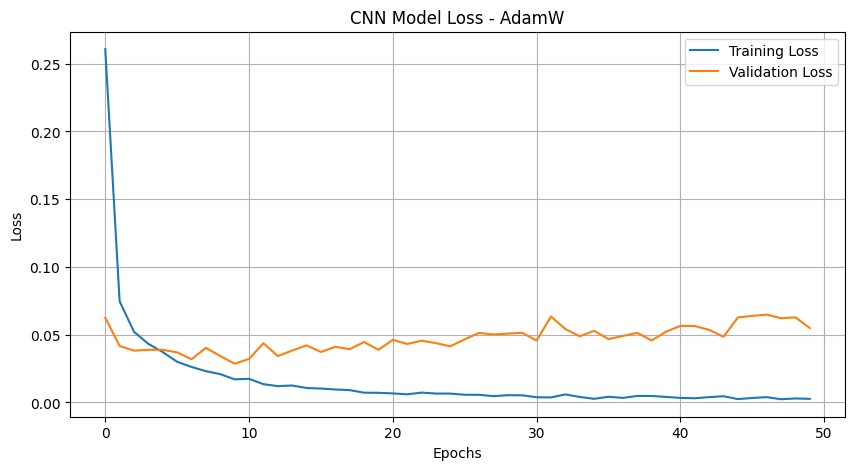

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'],
         label='Training Loss')

plt.plot(history.history['val_loss'],
         label='Validation Loss')

plt.title('CNN Model Loss - AdamW')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step


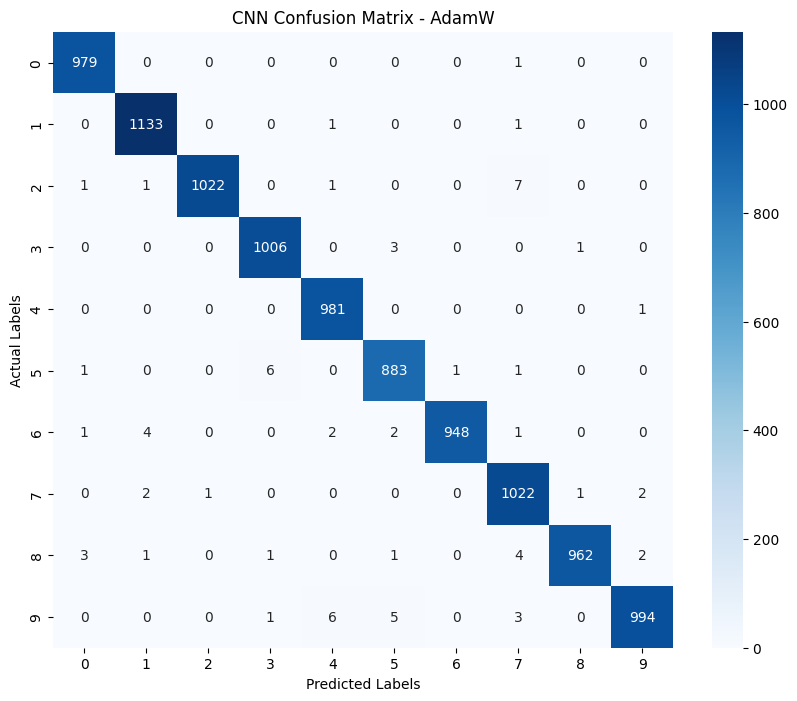

In [13]:
import numpy as np
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Predict test dataset
y_pred = model.predict(x_test)

# Convert probabilities into predicted classes
y_pred_classes = np.argmax(y_pred, axis=1)

# Actual labels
y_true = y_test

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title('CNN Confusion Matrix - AdamW')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')

plt.show()

In [14]:
print("Classification Report:")

print(classification_report(
    y_true,
    y_pred_classes,
    digits=4
))

Classification Report:
              precision    recall  f1-score   support

           0     0.9939    0.9990    0.9964       980
           1     0.9930    0.9982    0.9956      1135
           2     0.9990    0.9903    0.9946      1032
           3     0.9921    0.9960    0.9941      1010
           4     0.9899    0.9990    0.9944       982
           5     0.9877    0.9899    0.9888       892
           6     0.9989    0.9896    0.9942       958
           7     0.9827    0.9942    0.9884      1028
           8     0.9979    0.9877    0.9928       974
           9     0.9950    0.9851    0.9900      1009

    accuracy                         0.9930     10000
   macro avg     0.9930    0.9929    0.9929     10000
weighted avg     0.9930    0.9930    0.9930     10000

